<a href="https://colab.research.google.com/github/kayvour/FocusPen/blob/main/final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

CSV_PATH = "/content/pen.csv"

FEATURES = [
    "ax_g", "ay_g", "az_g",
    "gx_dps", "gy_dps", "gz_dps"
]

WINDOW = 30
STRIDE = 15

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU devices: []


In [ ]:
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        "Could not find /content/pen.csv. Upload pen.csv using the Colab Files sidebar "
        "or uncomment and run the upload cell above."
    )

df = pd.read_csv(CSV_PATH)

required_columns = FEATURES + ["timestamp_ms", "label"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Original dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nMissing values in required columns:")
print(df[required_columns].isnull().sum())

display(df.head())


Original dataset shape: (9801, 9)

Columns:
['timestamp_ms', 'ax_g', 'ay_g', 'az_g', 'gx_dps', 'gy_dps', 'gz_dps', 'fsr_adc', 'label']

Label counts:
label
Idle         2745
Gripping     2610
Writing      2250
Fidgeting    2196
Name: count, dtype: int64

Missing values in required columns:
ax_g            0
ay_g            0
az_g            0
gx_dps          0
gy_dps          0
gz_dps          0
timestamp_ms    0
label           0
dtype: int64


,timestamp_ms,ax_g,ay_g,az_g,gx_dps,gy_dps,gz_dps,fsr_adc,label
0,118254,-0.827357,0.569738,0.095878,-9.225726,-73.046680,3.196386,1676,Fidgeting
1,82858,0.058167,-0.978760,0.181018,-4.150894,-10.825509,-8.717520,2020,Writing
2,220812,-0.005822,-0.000527,-0.924452,-6.861448,1.229384,-3.698380,197,Idle
3,339670,-0.031752,0.016932,-0.917312,-7.083901,1.322666,-3.604346,3183,Gripping
4,193880,-0.010490,0.006329,-0.926697,-6.624845,1.430585,-3.313657,230,Idle


In [ ]:
df = df.dropna(subset=required_columns).copy()
df["timestamp_ms"] = pd.to_numeric(df["timestamp_ms"], errors="coerce")
df = df.dropna(subset=["timestamp_ms"])
df = df.sort_values("timestamp_ms").reset_index(drop=True)

# Keep only rows with valid numeric sensor readings
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=FEATURES + ["label"]).reset_index(drop=True)
df["label"] = df["label"].astype(str)

print("Clean dataset shape:", df.shape)
print("\nLabel counts:")
print(df["label"].value_counts())

print("\nFirst timestamps:")
display(df[["timestamp_ms", "label"]].head(10))


Clean dataset shape: (9801, 9)

Label counts:
label
Idle         2745
Gripping     2610
Writing      2250
Fidgeting    2196
Name: count, dtype: int64

First timestamps:


,timestamp_ms,label
0,0,Writing
1,33,Writing
2,66,Writing
3,133,Writing
4,200,Writing
5,233,Writing
6,266,Writing
7,300,Writing
8,333,Writing
9,366,Writing


In [ ]:
encoder = LabelEncoder()
df["label_encoded"] = encoder.fit_transform(df["label"])

class_names = encoder.classes_.tolist()
num_classes = len(class_names)

print("Class mapping:")
for class_id, class_name in enumerate(class_names):
    print(f"{class_id}: {class_name}")

if num_classes < 2:
    raise ValueError("The dataset must contain at least two distinct labels.")


Class mapping:
0: Fidgeting
1: Gripping
2: Idle
3: Writing


In [ ]:
features = df[FEATURES].to_numpy(dtype=np.float32)
labels = df["label_encoded"].to_numpy(dtype=np.int64)

# Locate boundaries where the label changes
boundaries = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1, len(df)]

X_train_list, y_train_list = [], []
X_val_list, y_val_list = [], []
X_test_list, y_test_list = [], []

def add_windows(segment_x, segment_y, start, stop, X_out, y_out):
    # Window must fit entirely inside [start, stop)
    for i in range(start, stop - WINDOW + 1, STRIDE):
        X_out.append(segment_x[i:i + WINDOW])
        # All rows in a segment have the same label
        y_out.append(segment_y[i + WINDOW - 1])

for seg_start, seg_end in zip(boundaries[:-1], boundaries[1:]):
    segment_x = features[seg_start:seg_end]
    segment_y = labels[seg_start:seg_end]
    n = len(segment_x)

    if n < 3 * WINDOW:
        print(f"Skipping short segment of {n} rows.")
        continue

    train_cut = int(n * 0.70)
    val_cut = int(n * 0.85)

    # Keep a WINDOW-sized gap around split boundaries
    train_stop = max(0, train_cut - WINDOW)
    val_start = min(n, train_cut + WINDOW)
    val_stop = max(val_start, val_cut - WINDOW)
    test_start = min(n, val_cut + WINDOW)

    add_windows(segment_x, segment_y, 0, train_stop, X_train_list, y_train_list)
    add_windows(segment_x, segment_y, val_start, val_stop, X_val_list, y_val_list)
    add_windows(segment_x, segment_y, test_start, n, X_test_list, y_test_list)

X_train = np.asarray(X_train_list, dtype=np.float32)
y_train = np.asarray(y_train_list, dtype=np.int64)
X_val = np.asarray(X_val_list, dtype=np.float32)
y_val = np.asarray(y_val_list, dtype=np.int64)
X_test = np.asarray(X_test_list, dtype=np.float32)
y_test = np.asarray(y_test_list, dtype=np.int64)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise ValueError("A split has no windows. Check the dataset and window settings.")

print("\nTraining window counts by class:")
print(pd.Series(encoder.inverse_transform(y_train)).value_counts())
print("\nValidation window counts by class:")
print(pd.Series(encoder.inverse_transform(y_val)).value_counts())
print("\nTest window counts by class:")
print(pd.Series(encoder.inverse_transform(y_test)).value_counts())


X_train: (444, 30, 6) y_train: (444,)
X_val:   (76, 30, 6) y_val:   (76,)
X_test:  (85, 30, 6) y_test:  (85,)

Training window counts by class:
Idle         125
Gripping     118
Writing      102
Fidgeting     99
Name: count, dtype: int64

Validation window counts by class:
Idle         22
Gripping     21
Writing      17
Fidgeting    16
Name: count, dtype: int64

Test window counts by class:
Idle         24
Gripping     23
Fidgeting    19
Writing      19
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()
n_features = len(FEATURES)

scaler.fit(X_train.reshape(-1, n_features))

def scale_windows(X):
    original_shape = X.shape
    X_scaled = scaler.transform(X.reshape(-1, n_features))
    return X_scaled.reshape(original_shape).astype(np.float32)

X_train = scale_windows(X_train)
X_val = scale_windows(X_val)
X_test = scale_windows(X_test)

print("Normalized training shape:", X_train.shape)
print("Feature means (training):", np.round(scaler.mean_, 4))
print("Feature scales (training):", np.round(scaler.scale_, 4))


Normalized training shape: (444, 30, 6)
Feature means (training): [-0.024  -0.0744 -0.5628 -6.9365  1.6097 -2.6609]
Feature scales (training): [ 0.2606  0.5567  0.4809 45.7041 74.4005 52.5363]


In [ ]:
from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(WINDOW, n_features), name="imu_window")
x = inputs

for dilation in [1, 2, 4]:
    residual = x

    x = layers.Conv1D(
        filters=64,
        kernel_size=3,
        padding="causal",
        dilation_rate=dilation,
        activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)

    if residual.shape[-1] != 64:
        residual = layers.Conv1D(64, kernel_size=1, padding="same")(residual)

    x = layers.Add()([x, residual])
    x = layers.Activation("relu")(x)

x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax", name="class_probabilities")(x)

model = Model(inputs, outputs, name="FocusPen_TCN")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "FocusPen_TCN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ imu_window          │ (None, 30, 6)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 64)    │      1,216 │ imu_window[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 30, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 30, 64)    │        448 │ imu_window[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 64)    │          0 │ dropout[0][0],    │
│                     │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 30, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 30, 64)    │     12,352 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 64)    │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 30, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 64)    │          0 │ dropout_1[0][0],  │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 30, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 30, 64)    │     12,352 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 64)    │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 30, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 30, 64)    │          0 │ dropout_2[0][0],  │
│                     │                   │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 30, 64)    │          0 │ add_2[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ activation_2[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 29,348 (114.64 KB)

 Trainable params: 28,964 (113.14 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=2,
        factor=0.5,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="/content/focuspen_tcn_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/30
12/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4283 - loss: 1.8490
Epoch 1: val_loss improved from None to 1.12436, saving model to /content/focuspen_tcn_best.keras

Epoch 1: finished saving model to /content/focuspen_tcn_best.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.5495 - loss: 1.3094 - val_accuracy: 0.2105 - val_loss: 1.1244 - learning_rate: 0.0010
Epoch 2/30
12/14 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6516 - loss: 0.7700
Epoch 2: val_loss improved from 1.12436 to 0.96100, saving model to /content/focuspen_tcn_best.keras

Epoch 2: finished saving model to /content/focuspen_tcn_best.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.7140 - loss: 0.6770 - val_accuracy: 0.5526 - val_loss: 0.9610 - learning_rate: 0.0010
Epoch 3/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7868 - loss: 0.5505
Epoch 3: val_loss improved from 0.96100 to 0.75592, saving model to /content/focuspen_tcn_best.keras

Epoch 3: finished saving mod

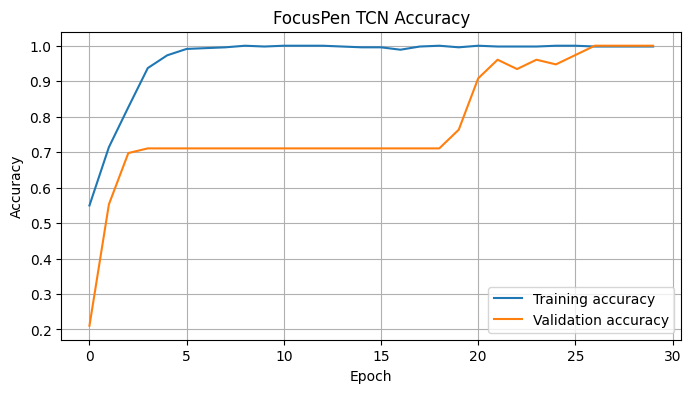

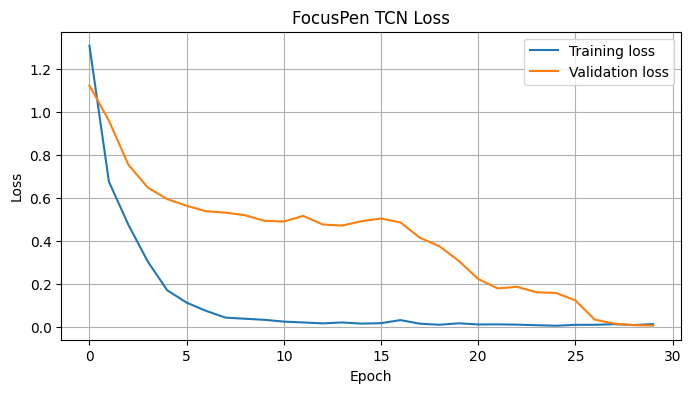

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("FocusPen TCN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("FocusPen TCN Loss")
plt.legend()
plt.grid(True)
plt.show()


Test loss: 0.0072
Test accuracy: 1.0000

Classification report:
              precision    recall  f1-score   support

   Fidgeting       1.00      1.00      1.00        19
    Gripping       1.00      1.00      1.00        23
        Idle       1.00      1.00      1.00        24
     Writing       1.00      1.00      1.00        19

    accuracy                           1.00        85
   macro avg       1.00      1.00      1.00        85
weighted avg       1.00      1.00      1.00        85



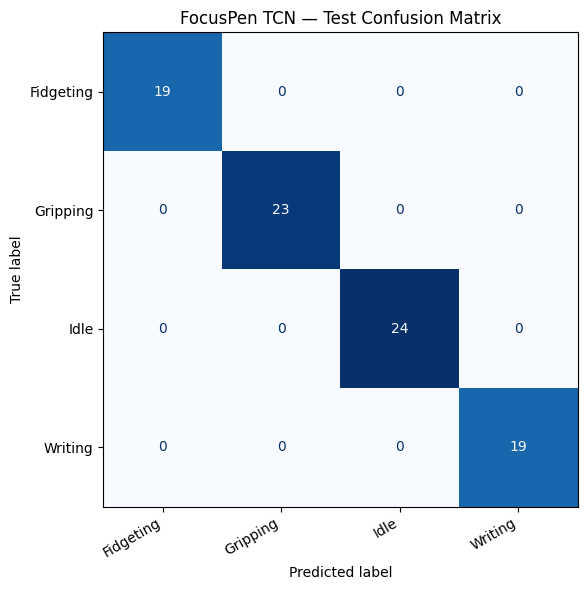

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("FocusPen TCN — Test Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
MODEL_PATH = "/content/focuspen_tcn.keras"
CLASSES_PATH = "/content/focuspen_classes.json"
PREPROCESS_PATH = "/content/focuspen_preprocessing.json"

model.save(MODEL_PATH)

with open(CLASSES_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

preprocessing = {
    "features": FEATURES,
    "window": WINDOW,
    "stride": STRIDE,
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "class_names": class_names
}

with open(PREPROCESS_PATH, "w") as f:
    json.dump(preprocessing, f, indent=2)

print("Saved:")
print(MODEL_PATH)
print(CLASSES_PATH)
print(PREPROCESS_PATH)


Saved:
/content/focuspen_tcn.keras
/content/focuspen_classes.json
/content/focuspen_preprocessing.json


In [ ]:
ZIP_PATH = "/content/focuspen_tcn_bundle.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(MODEL_PATH, arcname="focuspen_tcn.keras")
    zf.write(CLASSES_PATH, arcname="focuspen_classes.json")
    zf.write(PREPROCESS_PATH, arcname="focuspen_preprocessing.json")

print("Created:", ZIP_PATH)

# Uncomment to download directly to your computer:
# from google.colab import files
# files.download(ZIP_PATH)


Created: /content/focuspen_tcn_bundle.zip


In [ ]:
# Demo only: predict using one held-out test window
sample_window = X_test[-1:]  # shape: (1, WINDOW, n_features)

sample_probabilities = model.predict(sample_window, verbose=0)[0]
predicted_id = int(np.argmax(sample_probabilities))
predicted_label = class_names[predicted_id]

print("Predicted label:", predicted_label)
print("\nClass probabilities:")
for name, probability in zip(class_names, sample_probabilities):
    print(f"{name}: {probability:.3f}")


Predicted label: Gripping

Class probabilities:
Fidgeting: 0.000
Gripping: 0.998
Idle: 0.002
Writing: 0.000


In [ ]:
!pip install -q tf2onnx

In [ ]:
import tensorflow as tf
import tf2onnx

# Define model input:
# (batch_size, 30 timesteps, 6 IMU features)
input_signature = (
    tf.TensorSpec(
        shape=(None, 30, 6),
        dtype=tf.float32,
        name="imu_window"
    ),
)

# Export to ONNX
onnx_path = "/content/focuspen_tcn.onnx"

model_proto, _ = tf2onnx.convert.from_keras(
    model,
    input_signature=input_signature,
    opset=13,
    output_path=onnx_path
)

print("ONNX model saved to:", onnx_path)


ONNX model saved to: /content/focuspen_tcn.onnx


In [ ]:
from google.colab import files

files.download("/content/focuspen_tcn.onnx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>